In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    precision_score, recall_score, f1_score
)

In [2]:
df = pd.read_csv("../Datasets/student_pass_fail_final.csv")
df.sample(5)

,Study_Hours,Sleeping_Hours,Social_Media_Usage,Playing_Hours,Previous_Score,Attendance,Pass
124,3.051416,9.729192,4.191644,4.920417,94.0,87.0,1
122,3.862031,7.961184,4.849572,3.137527,45.0,59.0,0
113,8.273083,9.775890,4.330319,4.373508,98.0,80.0,1
16,3.738180,5.952398,1.466054,4.572060,65.0,93.0,1
111,2.450992,4.470738,2.091215,4.350494,98.0,51.0,1


In [3]:
df.shape

(210, 7)

In [4]:
df.isnull().sum()

Study_Hours           6
Sleeping_Hours        5
Social_Media_Usage    5
Playing_Hours         5
Previous_Score        5
Attendance            6
Pass                  0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(10)

In [6]:
df.fillna(df.mean(numeric_only=True), inplace=True)

,Study_Hours,Sleeping_Hours,Social_Media_Usage,Playing_Hours,Previous_Score,Attendance,Pass
0,4.370861,7.852190,0.515619,4.571494,44.0,51.000000,0
1,9.556429,4.504840,4.512765,0.588755,57.0,69.000000,1
2,7.587945,4.969772,2.526262,2.882582,67.0,50.000000,1
3,6.387926,9.391325,4.132287,1.370276,81.0,86.000000,1
4,2.404168,7.638574,2.610868,2.770890,61.0,58.000000,0
...,...,...,...,...,...,...,...
205,8.843145,8.175845,0.131835,4.695338,45.0,85.000000,1
206,9.881982,5.761551,4.816113,3.461383,54.0,55.000000,1
207,5.361662,4.604668,2.569947,3.791192,43.0,74.367647,0
208,6.806555,4.427132,4.311819,1.122203,59.0,96.000000,1


In [8]:
df.drop_duplicates(inplace=True)

print("Cleaned Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())

Cleaned Shape: (200, 7)
Remaining Missing Values: 0


In [9]:
X = df.drop(columns=["Pass"])
y = df["Pass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

Accuracy: 0.975
Precision: 0.9756756756756758
Recall: 0.975
F1-Score: 0.9733855185909981


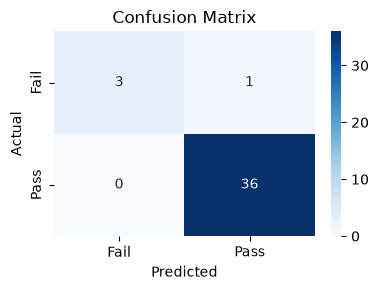

In [11]:
y_pred = model.prediy_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred, average="weighted", zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 3))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
student = pd.DataFrame([[8, 8, 2, 1, 67, 72]], columns=X.columns)
prediction = model.predict(scaler.transform(student))[0]

print("Student Details:")
print("Study Hours: 8")
print("Sleeping Hours: 8")
print("Social Media Usage: 2")
print("Playing Hours: 1")
print("Previous Score: 67")
print("Attendance: 72")
print("Final Prediction:", "Pass" if prediction == 1 else "Fail")

Student Details:
Study Hours: 8
Sleeping Hours: 8
Social Media Usage: 2
Playing Hours: 1
Previous Score: 67
Attendance: 72
Final Prediction: Pass
